# Phase 4 — Imbalanced Learning Experiments

**Project:** FraudShield AI  
**Goal:** compare a Logistic Regression baseline with class weighting, random undersampling, and SMOTE while avoiding data leakage.

By the end of this notebook, you should be able to explain why accuracy is misleading on rare-event data, what each strategy changes, why resampling belongs only inside the training pipeline, and how to compare these approaches on naturally imbalanced validation data.

> Run JupyterLab from the `fraudshield-ai` project root. The raw file `data/raw/creditcard.csv` must be present.

## 1. Why accuracy fails

The fraud class is rare. If a model predicts every transaction as legitimate, it can achieve very high accuracy but **zero recall** for fraud.

\[
	ext{Accuracy}=rac{TP+TN}{TP+TN+FP+FN},\quad
	ext{Recall}=rac{TP}{TP+FN},\quad
	ext{Precision}=rac{TP}{TP+FP}
\]

For this phase, we report accuracy for context, but use **Average Precision (AP)** as the primary model-selection metric. We also inspect precision, recall, F1, ROC-AUC, and the false-positive / false-negative counts. Precision, recall and F1 below use a fixed decision threshold of 0.5; AP and ROC-AUC measure ranking over thresholds.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
# nbconvert often starts from the notebook directory; resolve project root robustly.
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
DATA_PATH = ROOT / "data" / "raw" / "creditcard.csv"
assert DATA_PATH.exists(), f"Dataset not found: {DATA_PATH}"

print(f"Project root: {ROOT}")
print(f"Dataset: {DATA_PATH}")

Project root: /mnt/data/fraudshield-ai
Dataset: /mnt/data/fraudshield-ai/data/raw/creditcard.csv


## 2. Confirm the chronological split

We keep the existing Phase 3 split: 60% earliest transactions for training, 20% next for validation, and 20% latest for final test. Equal `Time` groups stay together. We do not rebalance validation/test because they should retain the class distribution that we need to evaluate against.

In [2]:
from src.data.splitting import chronological_train_validation_test_split

raw = pd.read_csv(DATA_PATH)
splits = chronological_train_validation_test_split(raw, time_column="Time", train_fraction=0.60, validation_fraction=0.20)
target = "Class"

split_summary = []
for name, part in [("train", splits.train), ("validation", splits.validation), ("test", splits.test)]:
    split_summary.append({
        "partition": name,
        "rows": len(part),
        "legitimate": int((part[target] == 0).sum()),
        "fraud": int((part[target] == 1).sum()),
        "fraud_rate_percent": float(part[target].mean() * 100),
        "time_min": float(part["Time"].min()),
        "time_max": float(part["Time"].max()),
    })
display(pd.DataFrame(split_summary))

validation = splits.validation
all_legitimate_accuracy = float((validation[target] == 0).mean())
print(f"All-legitimate dummy accuracy on validation: {all_legitimate_accuracy:.4%}")
print("Fraud cases caught by that dummy model: 0")

,partition,rows,legitimate,fraud,fraud_rate_percent,time_min,time_max
0,train,170888,170528,360,0.210664,0.0,120396.0
1,validation,56958,56901,57,0.100074,120397.0,145248.0
2,test,56961,56886,75,0.131669,145249.0,172792.0


All-legitimate dummy accuracy on validation: 99.8999%
Fraud cases caught by that dummy model: 0


In [3]:
train_counts = splits.train["Class"].value_counts().to_dict()
n_train = len(splits.train)
balanced_weights = {int(k): n_train / (2 * int(v)) for k, v in train_counts.items()}
print("Training class counts:", {int(k): int(v) for k, v in train_counts.items()})
print("Weights used by class_weight='balanced':", balanced_weights)

Training class counts: {0: 170528, 1: 360}
Weights used by class_weight='balanced': {0: 0.5010555451304185, 1: 237.34444444444443}


The dummy accuracy above is the lesson: accuracy by itself hides the fact that it never catches fraud.

## 3. What each strategy does

1. **Baseline:** keeps the original training distribution.
2. **Class weights (`class_weight='balanced'`):** increases the penalty for minority-class errors. It does not create or remove rows. The balanced weight for class \(k\) is based on \(n / (K\,n_k)\), where \(n_k\) is that class's training count.
3. **Random undersampling:** discards a portion of legitimate training rows to balance class counts. It is fast, but may discard useful legitimate behavior.
4. **SMOTE:** creates synthetic minority rows between minority-class neighbours. It can improve the learned decision boundary, but synthetic examples are not new real transactions and can create ambiguous points.

### Leakage rule

The imputer and scaler are fitted using training data only. For undersampling/SMOTE, the sampler is inside an `imblearn.pipeline.Pipeline`; it runs during `fit` only. Never call `fit_resample` on the whole dataset before making train/validation/test splits. See [imbalanced-learn's leakage warning](https://imbalanced-learn.org/stable/common_pitfalls.html).

In [4]:
from src.models.imbalance_experiments import make_experiment_pipeline

for strategy in ["baseline", "class_weight", "undersampling", "smote"]:
    print(f"\n--- {strategy} ---")
    display(make_experiment_pipeline(strategy, random_state=42, max_iter=1500))


--- baseline ---


,steps,"[('imputer', ...), ('scaler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",False
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True



--- class_weight ---


,steps,"[('imputer', ...), ('scaler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",False
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True



--- undersampling ---


,steps,"[('imputer', ...), ('scaler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",False
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True



--- smote ---


,steps,"[('imputer', ...), ('scaler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",False
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True


Notice the shared order: median imputation → standardization → optional sampler → Logistic Regression. Scaling is performed before SMOTE because nearest-neighbour distances are scale-sensitive. The sampler only sees the training examples during fitting.

## 4. Run all four experiments

This cell trains each approach on the same training partition and evaluates it on validation. It selects a strategy using validation AP, then refits that strategy on train + validation and evaluates the test partition once. Test results are not used to choose an approach or a threshold.

In [5]:
from src.models.imbalance_experiments import run_imbalance_experiments

report = run_imbalance_experiments(
    data_path=DATA_PATH,
    output_dir=ROOT / "reports" / "imbalance",
    model_path=ROOT / "models" / "logistic_regression_imbalance_best.joblib",
    threshold=0.5,
    random_state=42,
)
print("Selected by validation AP:", report["selected_experiment"])
print("Validation AP gap to runner-up:", report["validation_ap_gap_to_runner_up"])

Finished Baseline (no resampling): validation AP=0.65038, fit=1.5s


Finished Class weights (balanced): validation AP=0.77203, fit=1.9s


Finished Random undersampling: validation AP=0.45953, fit=0.7s


Finished SMOTE oversampling: validation AP=0.77347, fit=2.7s


Selected by validation AP: SMOTE oversampling
Validation AP gap to runner-up: 0.0014393603051182646


In [6]:
results = pd.DataFrame(report["validation_results"])
columns = [
    "experiment", "train_rows_after_strategy", "accuracy", "precision", "recall", "f1",
    "roc_auc", "pr_auc_average_precision", "false_positive", "false_negative", "fit_seconds"
]
display(results[columns].round(5))

,experiment,train_rows_after_strategy,accuracy,precision,recall,f1,roc_auc,pr_auc_average_precision,false_positive,false_negative,fit_seconds
0,SMOTE oversampling,341056,0.97333,0.03201,0.87719,0.06177,0.96524,0.77347,1512,7,2.663
1,Class weights (balanced),170888,0.96770,0.02706,0.89474,0.05252,0.97123,0.77203,1834,6,1.948
2,Baseline (no resampling),170888,0.99921,0.64286,0.47368,0.54545,0.96779,0.65038,15,30,1.496
3,Random undersampling,720,0.96993,0.02901,0.89474,0.05620,0.96753,0.45953,1707,6,0.722


## 5. Interpret the results

Do not assume the strategy that catches the most fraud is the best operational choice. In these experiments, class weighting and SMOTE improve validation AP and recall compared with the unweighted baseline, but at threshold 0.5 they also produce many more false positives. Random undersampling is fastest, but its AP is substantially lower on this data.

The selected model is chosen by **validation AP**, not by test performance. If top AP values are close, treat that as a near-tie—especially because the validation period contains only a small number of fraud cases. Threshold optimization is intentionally deferred to a later phase.

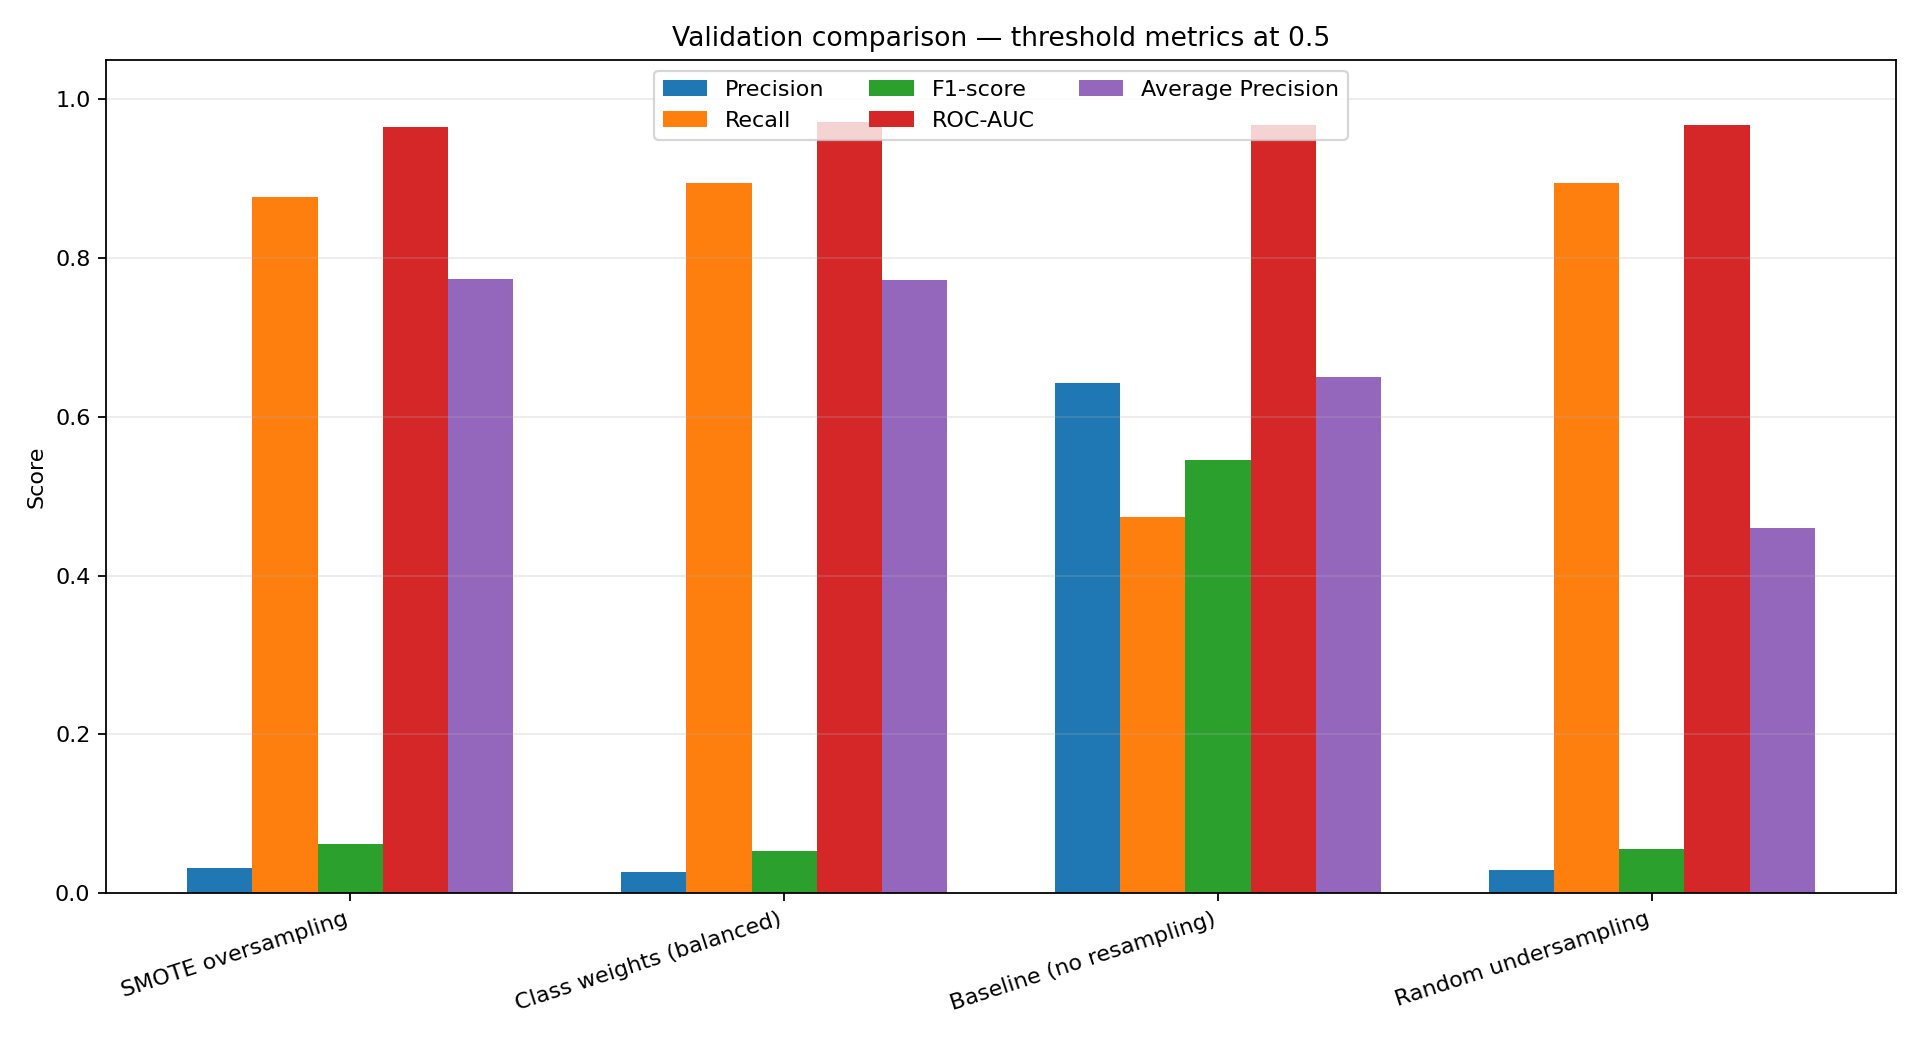

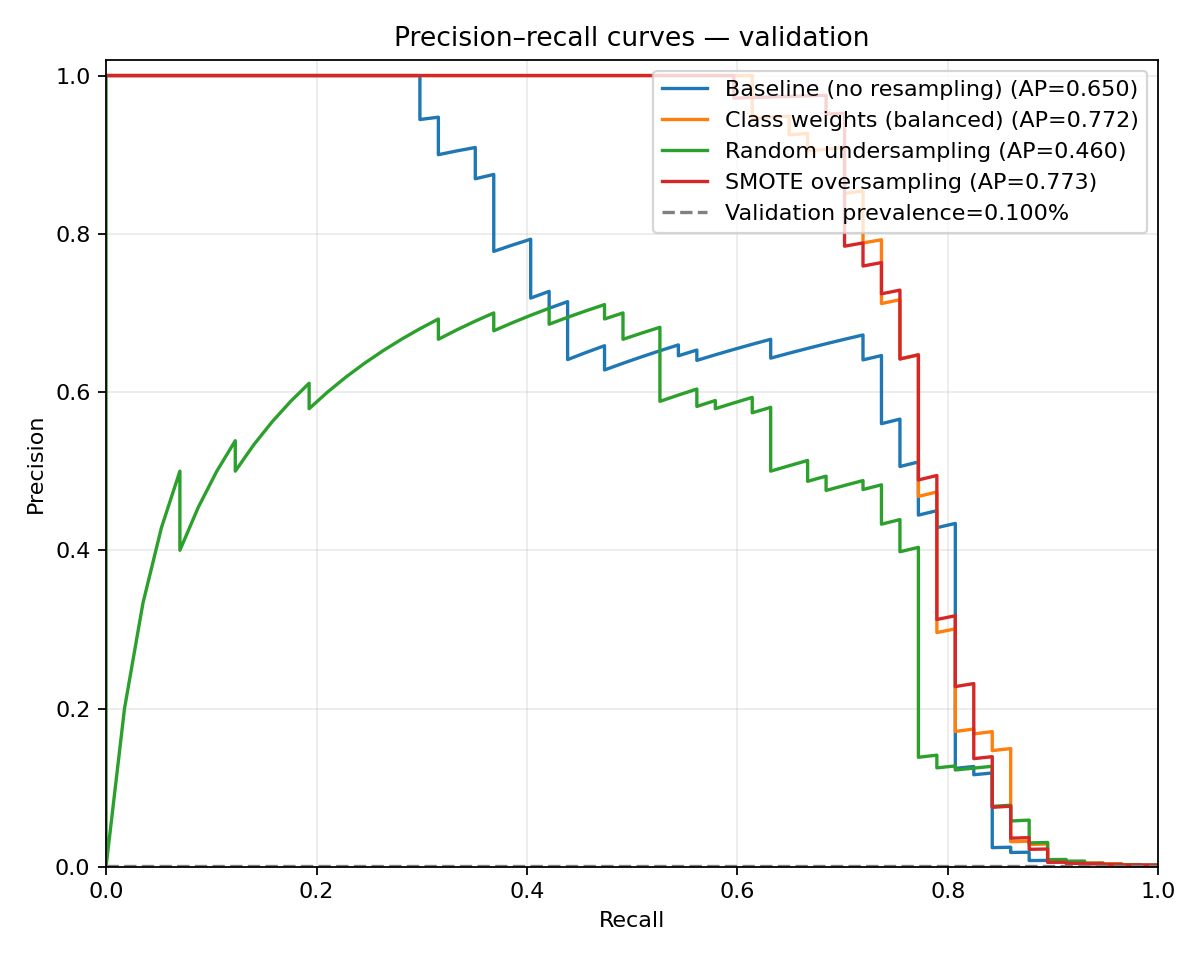

In [7]:
display(Image(filename=str(ROOT / "reports" / "imbalance" / "validation_metric_comparison.png")))
display(Image(filename=str(ROOT / "reports" / "imbalance" / "validation_precision_recall_curves.png")))

## 6. Test performance for the validation-selected strategy

Only the selected strategy is reported on the held-out test partition. The fixed threshold remains 0.5; it has not been optimized. Compare the model's precision and recall against the project requirements before considering deployment.

,test_value
threshold,0.500000
n_samples,56961.000000
n_positive_actual,75.000000
n_negative_actual,56886.000000
accuracy,0.983708
precision,0.067005
recall,0.880000
f1,0.124528
roc_auc,0.985953
pr_auc_average_precision,0.772896


Confusion matrix (rows=true class 0,1; columns=predicted class 0,1):
[[55967, 919], [9, 66]]


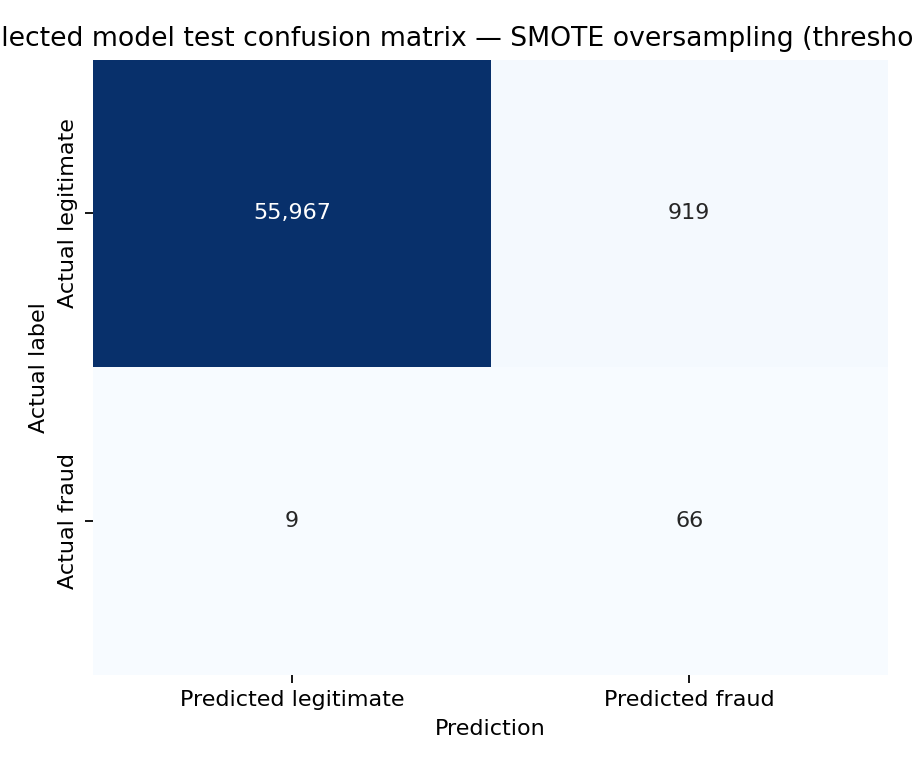

In [8]:
test_metrics = report["selected_model_test_metrics"]
display(pd.DataFrame([test_metrics]).T.rename(columns={0: "test_value"}))
print("Confusion matrix (rows=true class 0,1; columns=predicted class 0,1):")
print(report["selected_model_test_confusion_matrix_labels_0_1"])
display(Image(filename=str(ROOT / "reports" / "imbalance" / "confusion_matrix_test_selected.png")))

## 7. Resampling audit

Before moving on, confirm the following:

- [x] All approaches used the same chronological training/validation/test boundaries.
- [x] Imputer/scaler were fitted on training data only during model selection.
- [x] SMOTE and undersampling were inside an imbalanced-learn pipeline and only ran during `fit`.
- [x] Validation/test rows were not resampled.
- [x] Validation AP selected the strategy.
- [x] The selected strategy was refitted on train + validation before the test evaluation.
- [x] The threshold remained fixed at 0.5; no threshold tuning was performed here.

## 8. Generated artifacts

The script saves the validation comparison CSV, predictions for each validation model, metric/PR charts, the selected model's test metrics and predictions, a JSON summary, and this written report under `reports/imbalance/`.

**Next phase:** evaluate more systematic approaches (such as tuned XGBoost) and then choose a decision threshold based on an explicit false-positive / false-negative trade-off. Do not use the test set for tuning.